# SDXL × DrawBench — Z-Sampling (Colab)

Generates Z-Sampling images for SDXL on all 200 DrawBench prompts.

In [1]:
!pip install -q diffusers transformers accelerate safetensors

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
import gc
import json
import os
import shutil
import tempfile
import time
from dataclasses import dataclass
from pathlib import Path

import torch
from diffusers import DDIMInverseScheduler, DDIMScheduler, StableDiffusionXLPipeline
from diffusers.pipelines.stable_diffusion_xl.pipeline_output import StableDiffusionXLPipelineOutput
from diffusers.pipelines.stable_diffusion_xl.pipeline_stable_diffusion_xl import rescale_noise_cfg
from IPython.display import display
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
print(f"torch: {torch.__version__}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Device: cuda
torch: 2.11.0+cu128
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


## Config

In [ ]:
MODEL_ID = "stabilityai/stable-diffusion-xl-base-1.0"
HEIGHT = 1024
WIDTH = 1024
SEEDS = [42, 123, 2026]

# Z-Sampling hyperparameters (from the paper)
GAMMA_1 = 5.5        
GAMMA_2 = 0.0        
INFER_STEP = 50      
LAMBDA_STEP = None   
T_MAX = 1            

OUTPUT_DIR = Path("/content/outputs/daniel_sdxl_drawbench_zsampling")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DRIVE_DIR = Path("/content/drive/MyDrive/generative-modelling/sdxl_drawbench_zsampling")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_EVERY = 15  

# How many prompts to run. Set to None for all 200.
NUM_PROMPTS = None
PROMPT_SEED = 42

## DrawBench Prompts (200)

load the drawbench dataset from hugging face

In [6]:
import random
import pandas as pd

CSV_URL = "https://huggingface.co/datasets/sayakpaul/drawbench/raw/main/DrawBench%20Prompts%20-%20Sheet1.csv"
df = pd.read_csv(CSV_URL)
DRAWBENCH_PROMPTS = list(enumerate(df["Prompts"].tolist()))

if NUM_PROMPTS is not None and NUM_PROMPTS < len(DRAWBENCH_PROMPTS):
    rng = random.Random(PROMPT_SEED)
    selected_prompts = sorted(rng.sample(DRAWBENCH_PROMPTS, NUM_PROMPTS))
    print(f"Randomly selected {NUM_PROMPTS}/{len(DRAWBENCH_PROMPTS)} prompts (seed={PROMPT_SEED})")
else:
    selected_prompts = DRAWBENCH_PROMPTS
    print(f"Running all {len(selected_prompts)} prompts")

print(f"First 5: {[f'{i}: {p[:40]}...' for i, p in selected_prompts[:5]]}")
df.head()

Running all 200 prompts
First 5: ['0: A red colored car....', '1: A black colored car....', '2: A pink colored car....', '3: A black colored dog....', '4: A red colored dog....']


,Prompts,Category
0,A red colored car.,Colors
1,A black colored car.,Colors
2,A pink colored car.,Colors
3,A black colored dog.,Colors
4,A red colored dog.,Colors


## Load Pipeline

In [7]:
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

pipe = StableDiffusionXLPipeline.from_pretrained(
    MODEL_ID, torch_dtype=DTYPE, use_safetensors=True
)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
inverse_scheduler = DDIMInverseScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(DEVICE)

if DEVICE == "cuda":
    pipe.enable_attention_slicing()
    pipe.enable_vae_tiling()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:122: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

The config attributes {'interpolation_type': 'linear', 'use_karras_sigmas': False, 'skip_prk_steps': True} were passed to DDIMInverseScheduler, but are not expected and will be ignored. Please verify your scheduler_config.json configuration file.
/usr/local/lib/python3.12/dist-packages/diffusers/pipelines/pipeline_utils.py:2290: FutureWarning: `enable_vae_tiling` is deprecated and will be removed in version 0.40.0. Calling `enable_vae_tiling()` on a `StableDiffusionXLPipeline` is deprecated and this method will be removed in a future version. Please use `pipe.vae.enable_tiling()`.
  deprecate(


## Z-Sampling Implementation

duplicated from `/src`

In [8]:
@dataclass(frozen=True)
class ZSamplingConfig:
    gamma_1: float = 5.5
    gamma_2: float = 0.0
    infer_step: int = 50
    lambda_step: int | None = None
    t_max: int = 1

    def resolved_lambda_step(self) -> int:
        if self.lambda_step is None:
            return self.infer_step - 1
        return self.lambda_step


def _guided_noise_prediction(
    pipe, latents, timestep, prompt_embeds, add_text_embeds, add_time_ids,
    guidance_scale, guidance_rescale, timestep_cond,
):
    latent_model_input = torch.cat([latents] * 2) if pipe.do_classifier_free_guidance else latents
    latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, timestep)
    noise_pred = pipe.unet(
        latent_model_input, timestep,
        encoder_hidden_states=prompt_embeds,
        timestep_cond=timestep_cond,
        cross_attention_kwargs=pipe.cross_attention_kwargs,
        added_cond_kwargs={"text_embeds": add_text_embeds, "time_ids": add_time_ids},
        return_dict=False,
    )[0]
    if pipe.do_classifier_free_guidance:
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)
        if guidance_rescale > 0.0:
            noise_pred = rescale_noise_cfg(noise_pred, noise_pred_text, guidance_rescale=guidance_rescale)
    return noise_pred


def _decode_latents(pipe, latents, output_type):
    if output_type == "latent":
        return latents
    needs_upcasting = pipe.vae.dtype == torch.float16 and pipe.vae.config.force_upcast
    if needs_upcasting:
        pipe.upcast_vae()
        latents = latents.to(next(iter(pipe.vae.post_quant_conv.parameters())).dtype)
    has_latents_mean = hasattr(pipe.vae.config, "latents_mean") and pipe.vae.config.latents_mean is not None
    has_latents_std = hasattr(pipe.vae.config, "latents_std") and pipe.vae.config.latents_std is not None
    if has_latents_mean and has_latents_std:
        latents_mean = torch.tensor(pipe.vae.config.latents_mean).view(1, 4, 1, 1).to(latents.device, latents.dtype)
        latents_std = torch.tensor(pipe.vae.config.latents_std).view(1, 4, 1, 1).to(latents.device, latents.dtype)
        latents = latents * latents_std / pipe.vae.config.scaling_factor + latents_mean
    else:
        latents = latents / pipe.vae.config.scaling_factor
    image = pipe.vae.decode(latents, return_dict=False)[0]
    if needs_upcasting:
        pipe.vae.to(dtype=torch.float16)
    if pipe.watermark is not None:
        image = pipe.watermark.apply_watermark(image)
    return pipe.image_processor.postprocess(image, output_type=output_type)


@torch.no_grad()
def z_sample_sdxl(
    pipe, inverse_scheduler, prompt, *,
    config=None, height=1024, width=1024,
    negative_prompt=None, generator=None, latents=None,
    output_type="pil", guidance_rescale=0.0,
):
    """Run SDXL Z-Sampling. Standalone version for Colab (no ModelHandle needed)."""
    config = config or ZSamplingConfig()
    lambda_step = config.resolved_lambda_step()

    original_size = (height, width)
    target_size = (height, width)
    crops_coords_top_left = (0, 0)

    pipe._guidance_scale = config.gamma_1
    pipe._guidance_rescale = guidance_rescale
    pipe._clip_skip = None
    pipe._cross_attention_kwargs = None
    pipe._denoising_end = None
    pipe._interrupt = False

    batch_size = 1 if isinstance(prompt, str) else len(prompt)
    device = pipe._execution_device

    (prompt_embeds, negative_prompt_embeds,
     pooled_prompt_embeds, negative_pooled_prompt_embeds) = pipe.encode_prompt(
        prompt=prompt, prompt_2=None, device=device,
        num_images_per_prompt=1,
        do_classifier_free_guidance=pipe.do_classifier_free_guidance,
        negative_prompt=negative_prompt,
    )

    pipe.scheduler.set_timesteps(config.infer_step, device=device)
    timesteps = pipe.scheduler.timesteps
    num_inference_steps = len(timesteps)
    inverse_scheduler.set_timesteps(num_inference_steps, device=device)

    latents = pipe.prepare_latents(
        batch_size, pipe.unet.config.in_channels,
        height, width, prompt_embeds.dtype, device, generator, latents,
    )
    extra_step_kwargs = pipe.prepare_extra_step_kwargs(generator, 0.0)

    add_text_embeds = pooled_prompt_embeds
    if pipe.text_encoder_2 is None:
        text_encoder_projection_dim = int(pooled_prompt_embeds.shape[-1])
    else:
        text_encoder_projection_dim = pipe.text_encoder_2.config.projection_dim

    add_time_ids = pipe._get_add_time_ids(
        original_size, crops_coords_top_left, target_size,
        dtype=prompt_embeds.dtype,
        text_encoder_projection_dim=text_encoder_projection_dim,
    )
    negative_add_time_ids = add_time_ids

    if pipe.do_classifier_free_guidance:
        prompt_embeds = torch.cat([negative_prompt_embeds, prompt_embeds], dim=0)
        add_text_embeds = torch.cat([negative_pooled_prompt_embeds, add_text_embeds], dim=0)
        add_time_ids = torch.cat([negative_add_time_ids, add_time_ids], dim=0)

    prompt_embeds = prompt_embeds.to(device)
    add_text_embeds = add_text_embeds.to(device)
    add_time_ids = add_time_ids.to(device).repeat(batch_size, 1)

    timestep_cond = None

    for i, timestep in enumerate(timesteps):
        noise_pred = _guided_noise_prediction(
            pipe, latents, timestep, prompt_embeds,
            add_text_embeds, add_time_ids, config.gamma_1, guidance_rescale, timestep_cond,
        )
        pipe.scheduler._step_index = None
        next_latents = pipe.scheduler.step(
            noise_pred, timestep, latents, **extra_step_kwargs, return_dict=False,
        )[0]

        if i < lambda_step:
            for _ in range(config.t_max):
                # Zag: inversion with weak guidance
                inv_noise_pred = _guided_noise_prediction(
                    pipe, next_latents, timestep, prompt_embeds,
                    add_text_embeds, add_time_ids, config.gamma_2, guidance_rescale, timestep_cond,
                )
                inverse_scheduler._step_index = None
                inv_latents = inverse_scheduler.step(
                    inv_noise_pred, timesteps[i + 1], next_latents, return_dict=False,
                )[0]

                # Zig: forward denoising with strong guidance
                fwd_noise_pred = _guided_noise_prediction(
                    pipe, inv_latents, timestep, prompt_embeds,
                    add_text_embeds, add_time_ids, config.gamma_1, guidance_rescale, timestep_cond,
                )
                pipe.scheduler._step_index = None
                next_latents = pipe.scheduler.step(
                    fwd_noise_pred, timestep, inv_latents, **extra_step_kwargs, return_dict=False,
                )[0]

        latents = next_latents

    image = _decode_latents(pipe, latents, output_type)
    pipe.maybe_free_model_hooks()
    return StableDiffusionXLPipelineOutput(images=image)

## Generate

In [9]:
zsample_config = ZSamplingConfig(
    gamma_1=GAMMA_1,
    gamma_2=GAMMA_2,
    infer_step=INFER_STEP,
    lambda_step=LAMBDA_STEP,
    t_max=T_MAX,
)
print(f"Z-Sampling config: {zsample_config}")
print(f"Effective lambda_step: {zsample_config.resolved_lambda_step()}")
print(f"UNet evals per step (first {zsample_config.resolved_lambda_step()} steps): {1 + 2*T_MAX}")


def checkpoint_to_drive(files, tag):
    with tempfile.TemporaryDirectory() as tmp:
        for f in files:
            shutil.copy2(f, Path(tmp) / f.name)
        zp = shutil.make_archive(f"/content/{tag}", "zip", tmp)
    dest = DRIVE_DIR / f"{tag}.zip"
    shutil.copy2(zp, dest)
    os.sync()
    size_mb = Path(zp).stat().st_size / 1e6
    print(f"  >> Checkpoint saved: {dest.name} ({size_mb:.1f} MB, {len(files)} images)")


total = len(SEEDS) * len(selected_prompts)
done = 0

for seed in SEEDS:
    seed_dir = OUTPUT_DIR / f"seed{seed}"
    seed_dir.mkdir(parents=True, exist_ok=True)
    manifest = seed_dir / "manifest.jsonl"
    pending_files = []
    ckpt_count = 0

    for prompt_idx, prompt in selected_prompts:
        t0 = time.time()
        generator = torch.Generator(device=DEVICE).manual_seed(seed)

        result = z_sample_sdxl(
            pipe, inverse_scheduler, prompt,
            config=zsample_config,
            height=HEIGHT, width=WIDTH,
            generator=generator,
        )

        img = result.images[0]
        fname = f"sdxl_zsample_prompt{prompt_idx:03d}_seed{seed}.png"
        path = seed_dir / fname
        img.save(path)
        pending_files.append(path)
        del result, img
        torch.cuda.empty_cache()

        with open(manifest, "a") as f:
            f.write(json.dumps({
                "prompt_id": prompt_idx, "prompt": prompt, "seed": seed,
                "file": fname, "method": "z-sampling",
                "gamma_1": GAMMA_1, "gamma_2": GAMMA_2,
                "infer_step": INFER_STEP, "t_max": T_MAX,
            }) + "\n")

        done += 1
        elapsed = time.time() - t0
        print(f"[{done}/{total}] seed={seed} prompt={prompt_idx} ({elapsed:.1f}s)")

        if len(pending_files) == CHECKPOINT_EVERY:
            ckpt_count += 1
            checkpoint_to_drive(pending_files, f"sdxl_zsample_ckpt{ckpt_count}_seed{seed}")
            pending_files = []

    if pending_files:
        ckpt_count += 1
        checkpoint_to_drive(pending_files, f"sdxl_zsample_ckpt{ckpt_count}_seed{seed}")
        pending_files = []

print(f"\nDone. {done} images saved to {OUTPUT_DIR}")

Z-Sampling config: ZSamplingConfig(gamma_1=5.5, gamma_2=0.0, infer_step=50, lambda_step=None, t_max=1)
Effective lambda_step: 49
UNet evals per step (first 49 steps): 3


/usr/local/lib/python3.12/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:748: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(


[1/600] seed=42 prompt=0 (16.4s)
[2/600] seed=42 prompt=1 (15.0s)
[3/600] seed=42 prompt=2 (15.1s)
[4/600] seed=42 prompt=3 (15.1s)
[5/600] seed=42 prompt=4 (15.1s)
[6/600] seed=42 prompt=5 (15.1s)
[7/600] seed=42 prompt=6 (15.0s)
[8/600] seed=42 prompt=7 (14.9s)
[9/600] seed=42 prompt=8 (15.0s)
[10/600] seed=42 prompt=9 (15.0s)
[11/600] seed=42 prompt=10 (15.0s)
[12/600] seed=42 prompt=11 (15.1s)
[13/600] seed=42 prompt=12 (14.9s)
[14/600] seed=42 prompt=13 (15.1s)
[15/600] seed=42 prompt=14 (15.1s)
  >> Checkpoint saved: sdxl_zsample_ckpt1_seed42.zip (16.9 MB, 15 images)
[16/600] seed=42 prompt=15 (15.1s)
[17/600] seed=42 prompt=16 (15.1s)
[18/600] seed=42 prompt=17 (15.0s)
[19/600] seed=42 prompt=18 (15.1s)
[20/600] seed=42 prompt=19 (15.1s)
[21/600] seed=42 prompt=20 (15.1s)
[22/600] seed=42 prompt=21 (15.0s)
[23/600] seed=42 prompt=22 (15.0s)
[24/600] seed=42 prompt=23 (15.1s)
[25/600] seed=42 prompt=24 (15.1s)
[26/600] seed=42 prompt=25 (15.1s)
[27/600] seed=42 prompt=26 (15.1s)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (88 > 77). Running this sequence through the model will result in indexing errors
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer CLIPTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['rings on kthe end oc thei vatndlzes .']
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (88 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated bec

[111/600] seed=42 prompt=110 (15.0s)
[112/600] seed=42 prompt=111 (15.1s)


...

[313/600] seed=123 prompt=112 (15.1s)
[314/600] seed=123 prompt=113 (15.1s)
[315/600] seed=123 prompt=114 (15.1s)
[316/600] seed=123 prompt=115 (15.1s)
[317/600] seed=123 prompt=116 (15.1s)
[318/600] seed=123 prompt=117 (15.1s)
[319/600] seed=123 prompt=118 (15.1s)
[320/600] seed=123 prompt=119 (15.0s)
  >> Checkpoint saved: sdxl_zsample_ckpt8_seed123.zip (18.8 MB, 15 images)
[321/600] seed=123 prompt=120 (15.0s)
[322/600] seed=123 prompt=121 (15.0s)
[323/600] seed=123 prompt=122 (15.1s)
[324/600] seed=123 prompt=123 (14.9s)
[325/600] seed=123 prompt=124 (15.1s)
[326/600] seed=123 prompt=125 (15.1s)
[327/600] seed=123 prompt=126 (15.1s)
[328/600] seed=123 prompt=127 (15.1s)
[329/600] seed=123 prompt=128 (15.1s)
[330/600] seed=123 prompt=129 (15.1s)
[331/600] seed=123 prompt=130 (15.1s)
[332/600] seed=123 prompt=131 (15.0s)
[333/600] seed=123 prompt=132 (15.0s)
[334/600] seed=123 prompt=133 (15.1s)
[335/600] seed=123 prompt=134 (15.1s)
  >> Checkpoint saved: sdxl_zsample_ckpt9_seed123.z

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['rings on kthe end oc thei vatndlzes .']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['rings on kthe end oc thei vatndlzes .']


[511/600] seed=2026 prompt=110 (15.1s)
[512/600] seed=2026 prompt=111 (15.1s)


The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['can bce regulavewdd for lengh and vnolume y two or three pedalvs .']
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['can bce regulavewdd for lengh and vnolume y two or three pedalvs .']


[513/600] seed=2026 prompt=112 (15.1s)
[514/600] seed=2026 prompt=113 (15.0s)
[515/600] seed=2026 prompt=114 (15.1s)
[516/600] seed=2026 prompt=115 (15.1s)
[517/600] seed=2026 prompt=116 (15.0s)
[518/600] seed=2026 prompt=117 (14.9s)
[519/600] seed=2026 prompt=118 (15.1s)
[520/600] seed=2026 prompt=119 (15.1s)
  >> Checkpoint saved: sdxl_zsample_ckpt8_seed2026.zip (20.9 MB, 15 images)
[521/600] seed=2026 prompt=120 (15.1s)
[522/600] seed=2026 prompt=121 (15.0s)
[523/600] seed=2026 prompt=122 (15.1s)
[524/600] seed=2026 prompt=123 (15.0s)
[525/600] seed=2026 prompt=124 (14.9s)
[526/600] seed=2026 prompt=125 (15.0s)
[527/600] seed=2026 prompt=126 (15.1s)
[528/600] seed=2026 prompt=127 (15.1s)
[529/600] seed=2026 prompt=128 (15.1s)
[530/600] seed=2026 prompt=129 (15.1s)
[531/600] seed=2026 prompt=130 (15.1s)
[532/600] seed=2026 prompt=131 (15.0s)
[533/600] seed=2026 prompt=132 (15.1s)
[534/600] seed=2026 prompt=133 (15.1s)
[535/600] seed=2026 prompt=134 (15.1s)
  >> Checkpoint saved: sdxl

## Preview

sdxl_zsample_prompt196_seed42.png


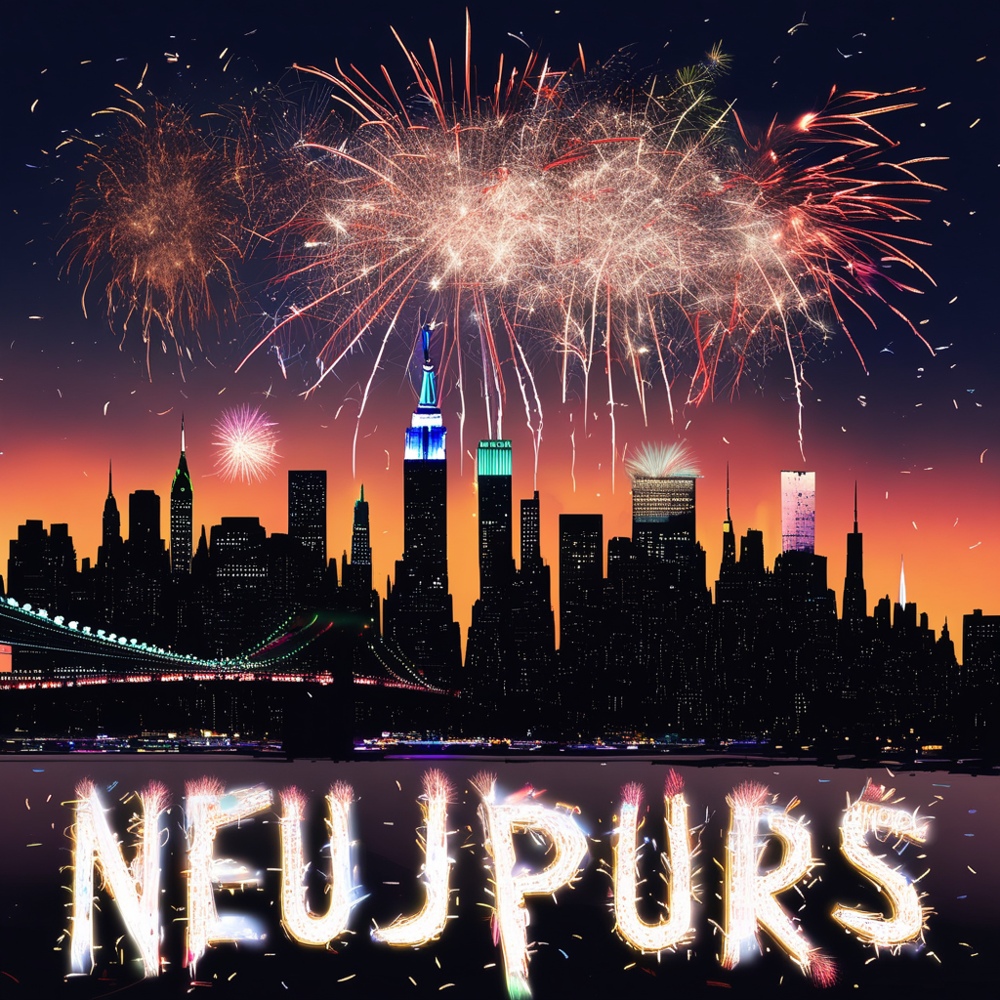

sdxl_zsample_prompt197_seed42.png


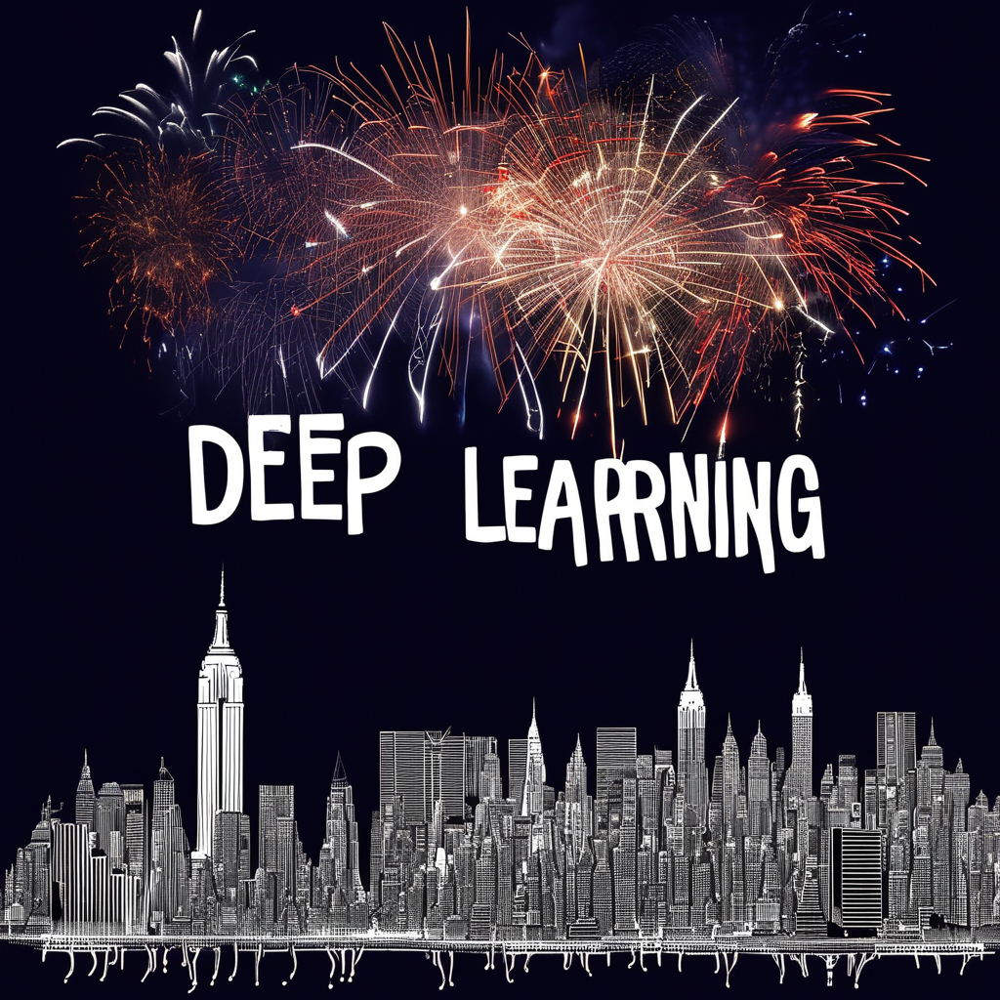

sdxl_zsample_prompt198_seed42.png


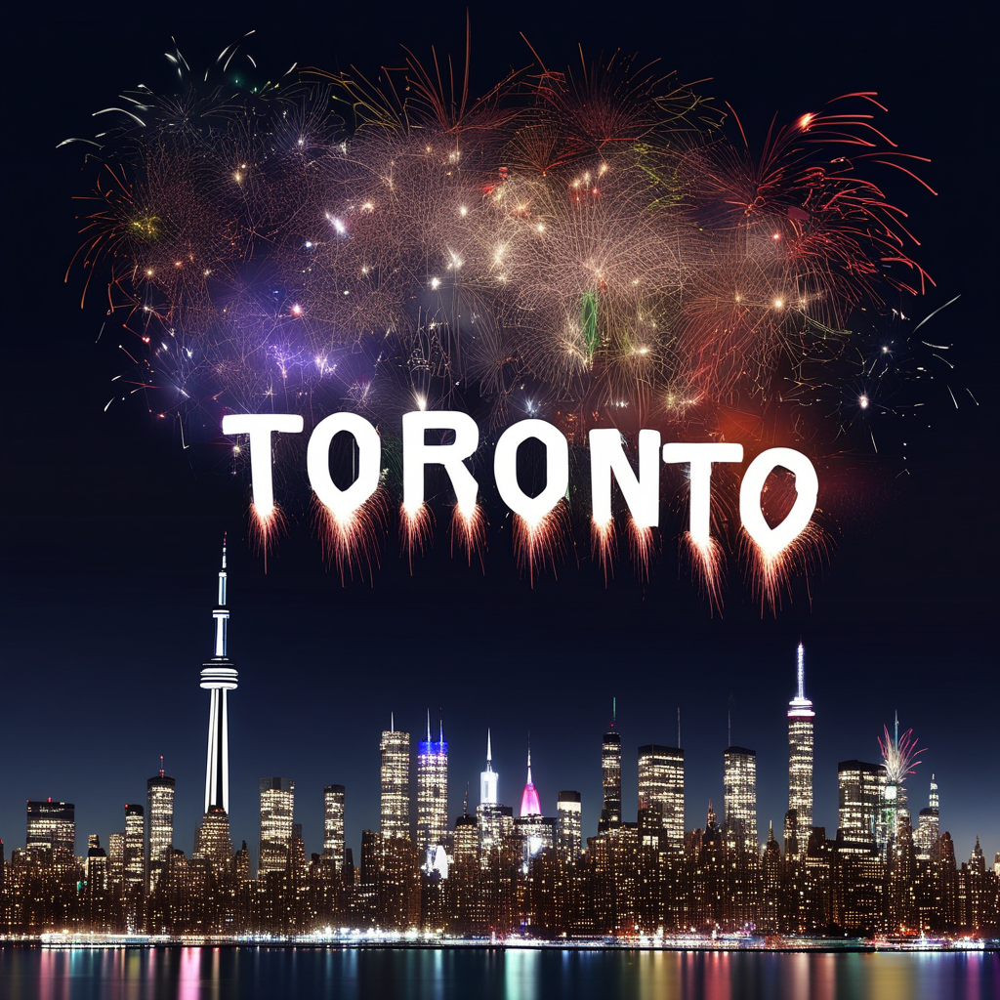

sdxl_zsample_prompt199_seed42.png


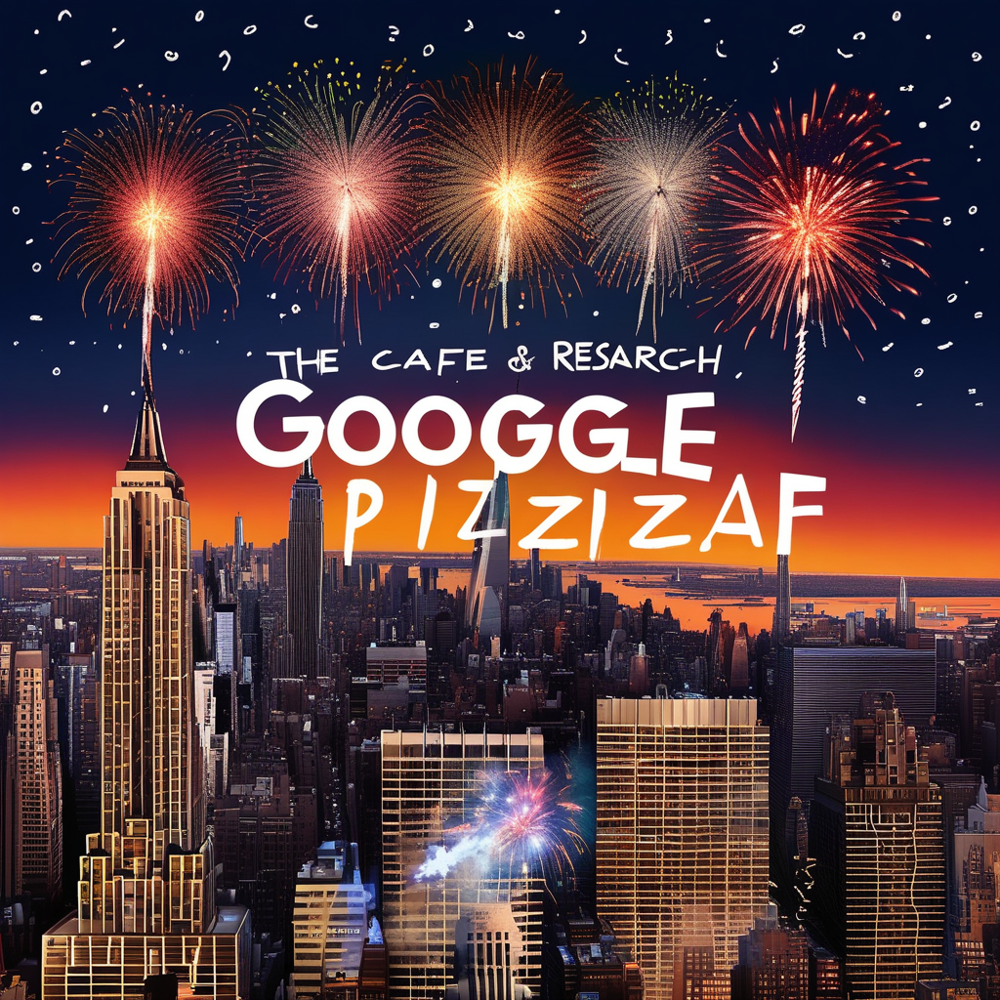

In [10]:
sample_paths = sorted(OUTPUT_DIR.rglob("*.png"))[-4:]
for p in sample_paths:
    print(p.name)
    display(Image.open(p))

## Copy to Google Drive

In [ ]:
for seed in SEEDS:
    seed_dir = OUTPUT_DIR / f"seed{seed}"
    if not seed_dir.exists():
        print(f"Skipping seed {seed} — no output dir")
        continue
    n = len(list(seed_dir.glob("*.png")))
    tag = f"sdxl_zsample_{n}imgs_seed{seed}_final"
    zp = shutil.make_archive(f"/content/{tag}", "zip", seed_dir)
    dest = DRIVE_DIR / f"{tag}.zip"
    shutil.copy2(zp, dest)
    print(f"{dest.name}: {Path(zp).stat().st_size / 1e6:.1f} MB")
os.sync()
print("All final zips flushed to Drive.")